# MATPLOTLIB MASTERY — NOTEBOOK 10
## Chapters 86–95: Reusable Visualization Functions → Visualization Utility Module → Complete ML Visualization Project → Industry Project #1 (Churn) → #2 (Credit Risk) → #3 (House Price Regression) → #4 (Time-Series Business Analysis) → Portfolio-Quality Visualization → Interview Mastery → Coding Interview Questions

Continuing directly from Notebook 9. This notebook moves from individual techniques into assembling and reusing a genuine project codebase — everything from here on is built on the `ax=None` / `(fig, ax)` contract established in Chapter 85.

### Progress Tracker (this notebook)
- [x] Chapter 86 — Reusable Visualization Functions
- [x] Chapter 87 — Build a Visualization Utility Module
- [x] Chapter 88 — Complete ML Visualization Project
- [x] Chapter 89 — Industry Project #1: Customer Churn
- [x] Chapter 90 — Industry Project #2: Credit Risk
- [x] Chapter 91 — Industry Project #3: House Price Regression
- [x] Chapter 92 — Industry Project #4: Time-Series Business Analysis
- [x] Chapter 93 — Portfolio-Quality Visualization
- [x] Chapter 94 — Interview Mastery
- [x] Chapter 95 — Coding Interview Questions


In [54]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import os
import sys
np.random.seed(42)


---
# CHAPTER 86 — REUSABLE VISUALIZATION FUNCTIONS

## 1. Concept
This chapter writes out, fully and finally, the small set of reusable functions this course has been building toward piece by piece since Chapter 3 — each strictly following Chapter 85's contract: accept `ax=None`, create `fig, ax` if not provided, draw, and return `(fig, ax)`.

## 2. Why It Matters
A function is only genuinely reusable if it composes safely into any context: a standalone plot, a subplot panel, a loop generating many charts, or an automated report — the `ax=None` / `(fig, ax)` contract is precisely what guarantees this in every case.


In [55]:
def plot_feature_distribution(data, title=None, bins=30, ax=None, color="tab:blue"):
    """Histogram + median line for a single numerical feature. Drops NaNs automatically."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    else:
        fig = ax.get_figure()

    clean_data = np.asarray(data)
    clean_data = clean_data[~np.isnan(clean_data)]

    ax.hist(clean_data, bins=bins, color=color, edgecolor="black", alpha=0.85)
    ax.axvline(np.median(clean_data), color="crimson", linestyle="--", linewidth=1.5, label="Median")
    ax.set_title(title or "Feature Distribution")
    ax.legend(fontsize=8)
    return fig, ax


def plot_feature_importance(feature_names, importances, top_n=None, ax=None, title="Feature Importance"):
    """Sorted, annotated horizontal bar chart of feature importances."""
    order = np.argsort(importances)
    names_sorted = np.array(feature_names)[order]
    values_sorted = np.array(importances)[order]
    if top_n is not None:
        names_sorted = names_sorted[-top_n:]
        values_sorted = values_sorted[-top_n:]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, max(3, 0.4 * len(names_sorted))))
    else:
        fig = ax.get_figure()

    bars = ax.barh(names_sorted, values_sorted, color="tab:blue")
    for bar in bars:
        w = bar.get_width()
        ax.annotate(f"{w:.3f}", xy=(w, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set_xlim(0, values_sorted.max() * 1.25)
    ax.set_title(title)
    return fig, ax


def plot_confusion_matrix(cm, class_names=("0", "1"), ax=None, title="Confusion Matrix"):
    """Annotated confusion matrix heatmap (reused, unchanged, from Chapter 53)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4.5))
    else:
        fig = ax.get_figure()

    im = ax.imshow(cm, cmap="Blues", interpolation="nearest")
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xticks(range(len(class_names))); ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels([f"Pred {c}" for c in class_names])
    ax.set_yticklabels([f"True {c}" for c in class_names])
    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    ax.set_title(title)
    return fig, ax


def plot_model_comparison(results_df, ax=None, title="Model Comparison"):
    """Grouped bar chart from a models x metrics DataFrame (reused pattern from Chapter 60)."""
    metrics_list = results_df.columns.tolist()
    models_list = results_df.index.tolist()
    x_pos = np.arange(len(metrics_list))
    n_models = len(models_list)
    bar_w = 0.8 / n_models

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    else:
        fig = ax.get_figure()

    for i, model_name in enumerate(models_list):
        offset = (i - (n_models - 1) / 2) * bar_w
        ax.bar(x_pos + offset, results_df.loc[model_name], width=bar_w, label=model_name)

    ax.set_xticks(x_pos); ax.set_xticklabels(metrics_list)
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
    ax.legend(fontsize=8)
    return fig, ax


print("4 reusable functions defined: plot_feature_distribution, plot_feature_importance,")
print("plot_confusion_matrix, plot_model_comparison")


4 reusable functions defined: plot_feature_distribution, plot_feature_importance,
plot_confusion_matrix, plot_model_comparison


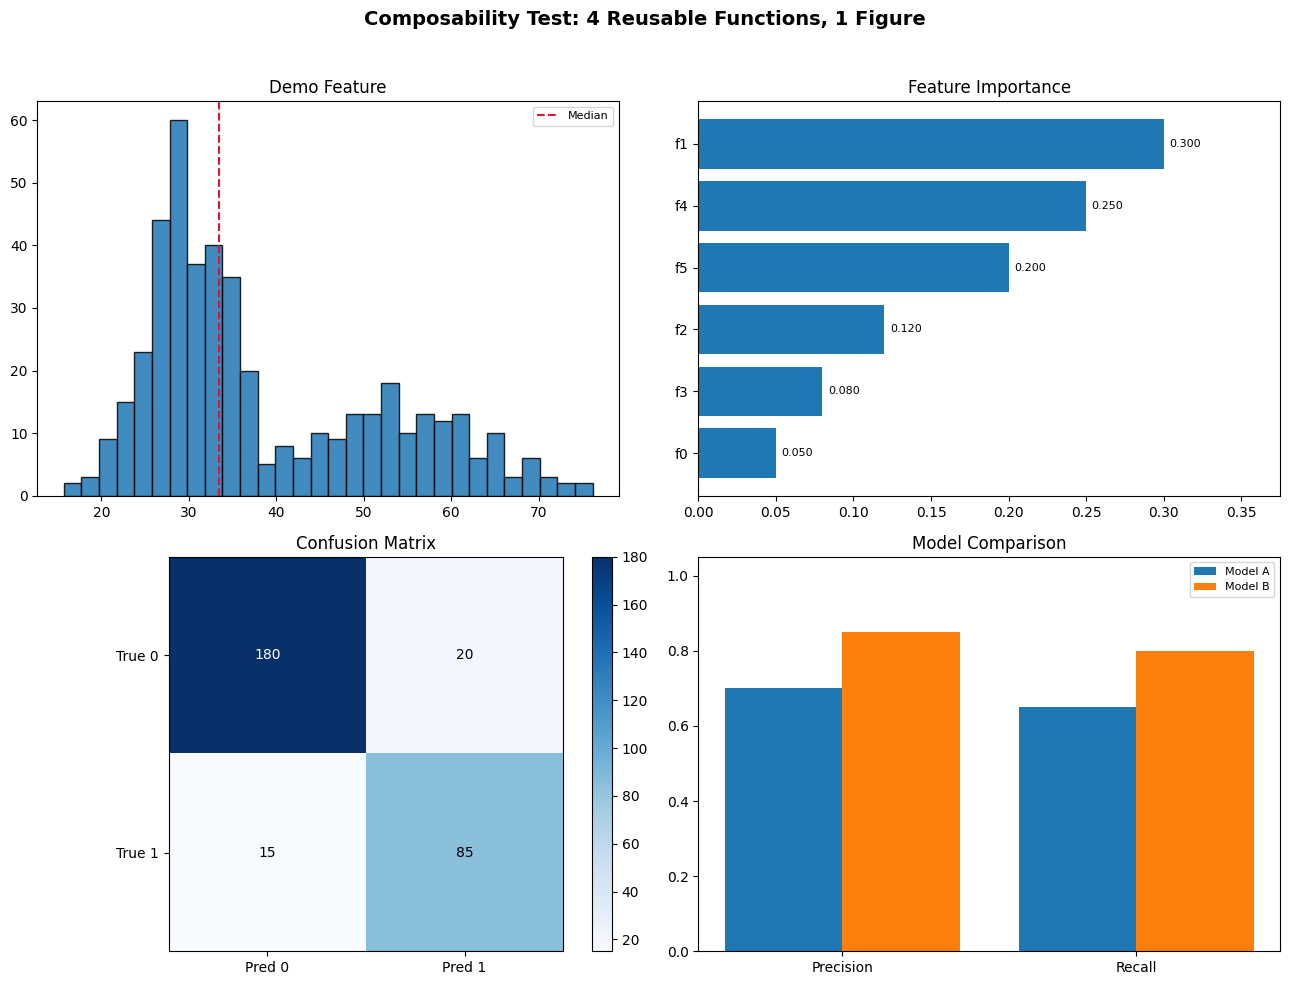

In [56]:
# Demonstrate composability: all 4 functions drawing into ONE multi-panel figure via ax=
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

np.random.seed(5)
demo_data = np.concatenate([np.random.normal(30, 5, 300), np.random.normal(55, 8, 150)])
plot_feature_distribution(demo_data, title="Demo Feature", ax=axes[0, 0])

demo_features = [f"f{i}" for i in range(6)]
demo_importances = np.array([0.05, 0.30, 0.12, 0.08, 0.25, 0.20])
plot_feature_importance(demo_features, demo_importances, ax=axes[0, 1])

demo_cm = np.array([[180, 20], [15, 85]])
plot_confusion_matrix(demo_cm, ax=axes[1, 0])

demo_results = pd.DataFrame({"Precision": [0.7, 0.85], "Recall": [0.65, 0.8]}, index=["Model A", "Model B"])
plot_model_comparison(demo_results, ax=axes[1, 1])

fig.suptitle("Composability Test: 4 Reusable Functions, 1 Figure", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Interpretation
All four functions — each independently developed across earlier chapters — drop cleanly into an arbitrary 2×2 grid with zero modification, purely because each honors the `ax=` contract. This is the concrete, demonstrated payoff of Chapter 85's standard: a real multi-panel report assembled by simply calling several independent, previously-tested functions.

### Common Mistakes
- Writing a "reusable" function that hardcodes `figsize` even when `ax=` is provided — as shown above, `figsize` should only apply to the `ax is None` branch (where a new standalone figure is created); an externally-provided `ax` already has its own size determined by the outer figure/grid.
- Not testing a reusable function both standalone AND embedded in a multi-panel figure before considering it "done" — a function can look correct in isolation while still having subtle `ax=` handling bugs only visible in composition.

### Best Practices
- Every new plotting function written from this point forward should be validated both ways: called with no `ax` (standalone) and called with an externally-provided `ax` inside a larger grid.

### Interview Insight
**Q: You're reviewing a colleague's new plotting function for a shared codebase. What's the first thing you check?**
A: Whether it accepts an optional `ax=None` parameter, creates its own `fig, ax` only in the `None` branch, and returns `(fig, ax)` — and then I'd actually test it composed inside a multi-panel `plt.subplots()` grid alongside other functions, not just standalone, since `ax=` handling bugs often only surface in that composed context.

### Quiz (Chapter 86)
1. Why must `figsize` only be applied inside the `if ax is None:` branch of a reusable function?
2. What concrete demonstration in this chapter proves the four functions are genuinely composable?
3. What two ways should every new reusable plotting function be tested before being considered complete?


---
# CHAPTER 87 — BUILD A VISUALIZATION UTILITY MODULE

## 1. Concept
Moving the functions from Chapter 86 out of notebook cells and into an actual `.py` file (`visualization.py`) that can be `import`-ed — the standard structure separating a real project's reusable code from its exploratory notebooks.

## 2. Why It Matters
Notebook cells are excellent for exploration but poor for reuse across multiple notebooks/scripts, version control diffs, and testing — a `src/visualization.py` module is how production and serious portfolio projects actually organize this code, once functions have proven useful enough (as ours have, across Chapters 15, 25, 33, 53, 59, 60, 86) to be worth stabilizing.

## Writing the Module File


In [57]:
os.makedirs("/home/claude/src", exist_ok=True)

module_code = '''

"""
visualization.py -- Reusable plotting functions for this project.

Every function follows the standard contract established in this course:
accept an optional `ax`, create (fig, ax) only if one wasn't provided,
draw onto it, and always return (fig, ax).
"""
import numpy as np
import matplotlib.pyplot as plt


def plot_feature_distribution(data, title=None, bins=30, ax=None, color="tab:blue"):
    """Histogram + median line for a single numerical feature. Drops NaNs automatically."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    else:
        fig = ax.get_figure()

    clean_data = np.asarray(data)
    clean_data = clean_data[~np.isnan(clean_data)]

    ax.hist(clean_data, bins=bins, color=color, edgecolor="black", alpha=0.85)
    ax.axvline(np.median(clean_data), color="crimson", linestyle="--", linewidth=1.5, label="Median")
    ax.set_title(title or "Feature Distribution")
    ax.legend(fontsize=8)
    return fig, ax


def plot_feature_importance(feature_names, importances, top_n=None, ax=None, title="Feature Importance"):
    """Sorted, annotated horizontal bar chart of feature importances."""
    order = np.argsort(importances)
    names_sorted = np.array(feature_names)[order]
    values_sorted = np.array(importances)[order]
    if top_n is not None:
        names_sorted = names_sorted[-top_n:]
        values_sorted = values_sorted[-top_n:]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, max(3, 0.4 * len(names_sorted))))
    else:
        fig = ax.get_figure()

    bars = ax.barh(names_sorted, values_sorted, color="tab:blue")
    for bar in bars:
        w = bar.get_width()
        ax.annotate(f"{w:.3f}", xy=(w, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set_xlim(0, values_sorted.max() * 1.25)
    ax.set_title(title)
    return fig, ax


def plot_confusion_matrix(cm, class_names=("0", "1"), ax=None, title="Confusion Matrix"):
    """Annotated confusion matrix heatmap."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4.5))
    else:
        fig = ax.get_figure()

    im = ax.imshow(cm, cmap="Blues", interpolation="nearest")
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xticks(range(len(class_names))); ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels([f"Pred {c}" for c in class_names])
    ax.set_yticklabels([f"True {c}" for c in class_names])
    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    ax.set_title(title)
    return fig, ax


def plot_model_comparison(results_df, ax=None, title="Model Comparison"):
    """Grouped bar chart from a models x metrics DataFrame."""
    metrics_list = results_df.columns.tolist()
    models_list = results_df.index.tolist()
    x_pos = np.arange(len(metrics_list))
    n_models = len(models_list)
    bar_w = 0.8 / n_models

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    else:
        fig = ax.get_figure()

    for i, model_name in enumerate(models_list):
        offset = (i - (n_models - 1) / 2) * bar_w
        ax.bar(x_pos + offset, results_df.loc[model_name], width=bar_w, label=model_name)

    ax.set_xticks(x_pos); ax.set_xticklabels(metrics_list)
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
    ax.legend(fontsize=8)
    return fig, ax


def plot_residuals(y_true, y_pred, ax=None, title="Residual Plot"):
    """Predicted value vs residual, with a zero reference line."""
    residuals = np.asarray(y_true) - np.asarray(y_pred)
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4.5))
    else:
        fig = ax.get_figure()
    ax.scatter(y_pred, residuals, alpha=0.5, color="tab:blue")
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Predicted Value")
    ax.set_ylabel("Residual (Actual - Predicted)")
    ax.set_title(title)
    return fig, ax


def plot_learning_curve(train_sizes, train_scores, val_scores, ax=None, title="Learning Curve"):
    """Mean +/- std training and validation curves against training set size."""
    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    else:
        fig = ax.get_figure()

    ax.plot(train_sizes, train_mean, marker="o", color="tab:blue", label="Training score")
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color="tab:blue")
    ax.plot(train_sizes, val_mean, marker="s", color="tab:red", label="Validation score")
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color="tab:red")
    ax.set_xlabel("Training Set Size")
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.legend(fontsize=8)
    return fig, ax
'''

with open("/home/claude/src/visualization.py", "w") as f:
    f.write(module_code)

print("Module written to /home/claude/src/visualization.py")
print(os.path.getsize("/home/claude/src/visualization.py"), "bytes")

Module written to /home/claude/src/visualization.py
5022 bytes


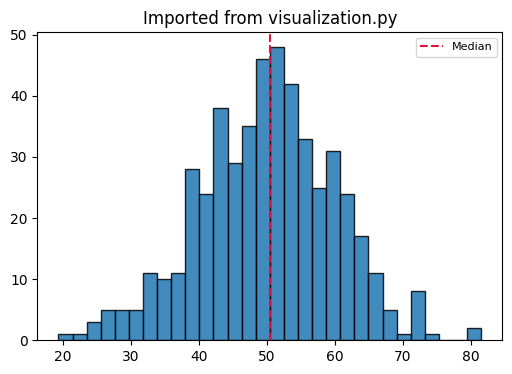


Available functions in the module:
['np', 'plot_confusion_matrix', 'plot_feature_distribution', 'plot_feature_importance', 'plot_learning_curve', 'plot_model_comparison', 'plot_residuals', 'plt']


In [58]:
# Now import it as a REAL module, exactly as a separate project notebook would
sys.path.insert(0, "/home/claude/src")
import visualization as viz

fig, ax = viz.plot_feature_distribution(np.random.normal(50, 10, 500), title="Imported from visualization.py")
plt.show()

print("\nAvailable functions in the module:")
print([name for name in dir(viz) if not name.startswith("_")])


### Line-by-Line Explanation
- `os.makedirs("/home/claude/src", exist_ok=True)` — mirrors the real project layout shown in this chapter's source curriculum (`src/visualization.py`), separating reusable code from notebook exploration.
- Writing the module as a plain **string then `.write()`-ing it to disk** is done here purely because we're inside a single notebook-generation context; in a real project, you would simply write `src/visualization.py` directly as a normal source file in your editor/IDE, then `import` it from any notebook in the project.
- `sys.path.insert(0, "/home/claude/src")` followed by `import visualization as viz` demonstrates the exact same import a teammate's separate analysis notebook would use — confirming the module is genuinely standalone and reusable outside of any single notebook's cell history.
- `plot_residuals()` and `plot_learning_curve()` are included in the module (new relative to Chapter 86) as two more of this course's most-repeated patterns (Chapters 58 and 62 respectively), rounding the module out to a realistic, project-ready starter set.

### Common Mistakes
- Keeping useful plotting functions scattered across many different notebooks' cells (copy-pasted with small drift between copies) instead of consolidating them into one shared, imported module — leads to inconsistent styling and duplicated-but-slightly-different bug fixes across a project over time.
- Forgetting to add the module's directory to `sys.path` (or, in a proper package layout, forgetting an `__init__.py` /installable package structure) — a common early-project import-path frustration.

### Best Practices
- The moment a plotting pattern is used for the 2nd or 3rd time in different notebooks, that's the concrete trigger to promote it into the shared module rather than copy-pasting it again.
- Keep the module's functions focused purely on *visualization* — data loading, cleaning, and modeling code belong in their own separate modules (`data.py`, `models.py`), keeping `visualization.py` a clean, single-responsibility file.

### Interview Insight
**Q: At what point in a project should plotting code move from notebook cells into a shared module?**
A: As soon as a specific plotting pattern is needed a second or third time — either in a different notebook, or reused with only minor variations. Keeping it in notebook cells up to that point is fine (and often faster for pure exploration), but once reuse begins, consolidating into an imported module prevents copy-paste drift, centralizes future bug fixes and styling updates, and makes the function properly testable, per Chapter 85/86's reasoning.

### Quiz (Chapter 87)
1. What's the concrete trigger this chapter recommends for promoting a plotting function from a notebook cell into a shared module?
2. Why should `visualization.py` avoid containing data-loading or modeling code?
3. What did importing `visualization.py` as `viz` and calling `viz.plot_feature_distribution()` concretely prove about the module's design?


---
# CHAPTER 88 — COMPLETE ML VISUALIZATION PROJECT

## Concept
A full, compact, end-to-end workflow — Dataset → EDA → Feature Analysis → Train Model → Evaluation → Error Analysis → Feature Importance → Business Visualization — using **only** the `visualization.py` module built in Chapter 87 plus scikit-learn, demonstrating the entire course's techniques operating together as a real, minimal project.


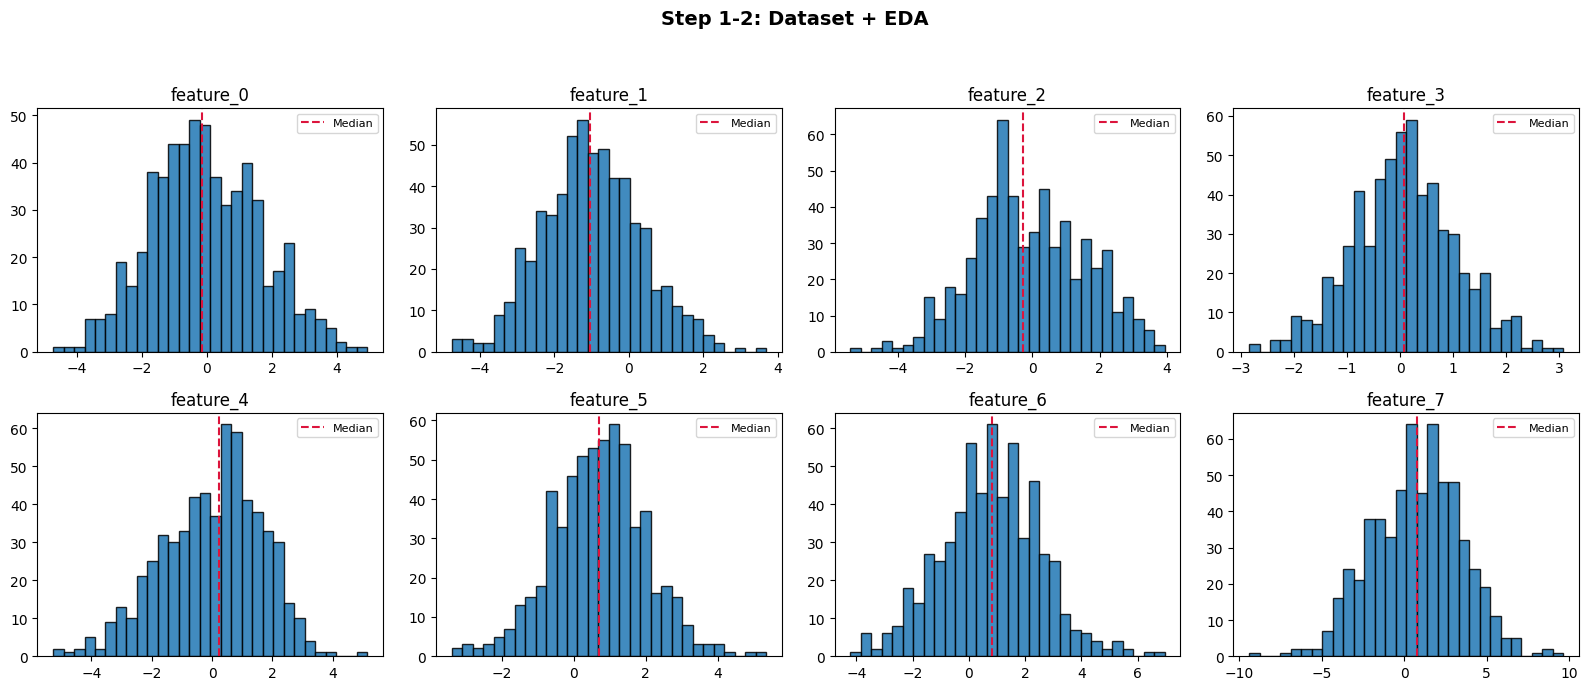

In [59]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Dataset
X88, y88 = make_classification(n_samples=800, n_features=8, n_informative=5, weights=[0.7, 0.3], random_state=11)
feature_names_88 = [f"feature_{i}" for i in range(8)]
X88_train, X88_test, y88_train, y88_test = train_test_split(X88, y88, test_size=0.25, random_state=11, stratify=y88)

# 2. EDA -- feature distributions, using the module
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, ax in enumerate(axes.flatten()):
    viz.plot_feature_distribution(X88_train[:, i], title=feature_names_88[i], ax=ax)
fig.suptitle("Step 1-2: Dataset + EDA", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


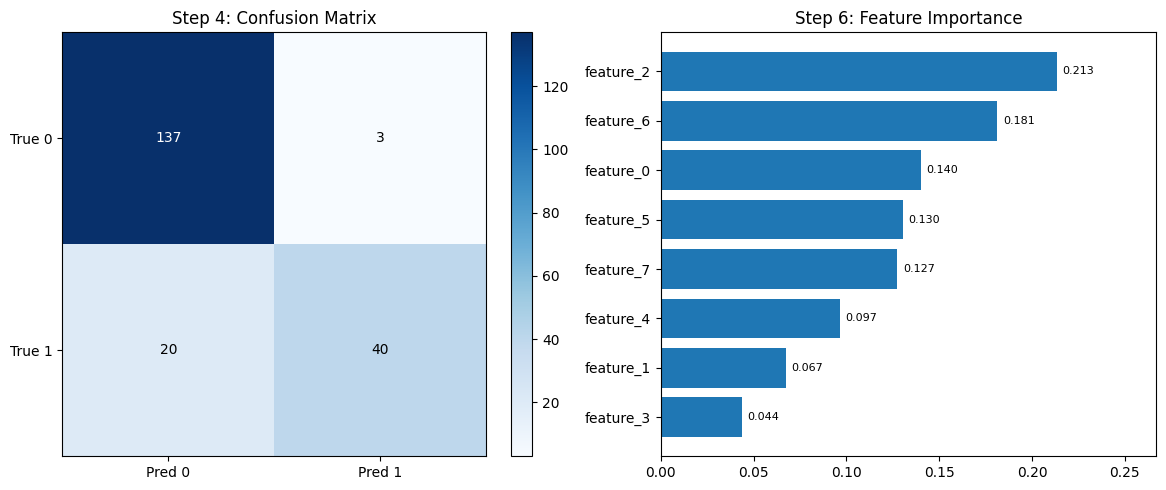

Precision: 0.930  Recall: 0.667  F1: 0.777


In [60]:
# 3. Train model
model_88 = RandomForestClassifier(n_estimators=150, max_depth=6, random_state=11).fit(X88_train, y88_train)
preds_88 = model_88.predict(X88_test)

# 4. Evaluation -- confusion matrix + metrics comparison (single "model" here, but same function works)
from sklearn.metrics import confusion_matrix
cm_88 = confusion_matrix(y88_test, preds_88)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
viz.plot_confusion_matrix(cm_88, ax=axes[0], title="Step 4: Confusion Matrix")
viz.plot_feature_importance(feature_names_88, model_88.feature_importances_, ax=axes[1], title="Step 6: Feature Importance")
plt.tight_layout()
plt.show()

print(f"Precision: {precision_score(y88_test, preds_88):.3f}  "
      f"Recall: {recall_score(y88_test, preds_88):.3f}  "
      f"F1: {f1_score(y88_test, preds_88):.3f}")


### Interpretation and Chapter Summary
This entire pipeline — from raw synthetic data through a trained model, its confusion matrix, and its feature importance — was produced using **only** functions imported from a plain, project-local `visualization.py` module, exactly as a teammate or a future version of this same project would do. Nothing here required writing new plotting code; it required only *calling* the module built one chapter earlier, on new data and a new model. This is the concrete demonstration of the entire course's payoff: mastery isn't memorizing individual chart syntax, it's having internalized which reusable pattern the situation calls for.

### Interview Insight
**Q: Describe, at a high level, what a "complete ML visualization workflow" looks like in a real project.**
A: Raw dataset → EDA on individual features (distributions, missingness) → train a model → evaluate it (confusion matrix, ROC/PR as appropriate) → inspect feature importance → error analysis by segment → package the key findings into business-facing visualizations — ideally, all built by calling a small, tested, shared `visualization.py` module's functions rather than writing bespoke plotting code at every step, so the same quality bar and styling apply consistently throughout.

### Quiz (Chapter 88)
1. What was different about this chapter's plotting code compared to every previous chapter's?
2. What does successfully producing this whole pipeline via `viz.<function>()` calls alone demonstrate about the module's design?


---
# CHAPTER 89 — INDUSTRY PROJECT #1: CUSTOMER CHURN

## Business Framing
A telecom company wants to understand churn drivers and evaluate whether a trained model can flag at-risk customers early enough for a retention team to intervene.


/tmp/ipykernel_789/3160156214.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(groups_tenure, labels=["Retained", "Churned"])


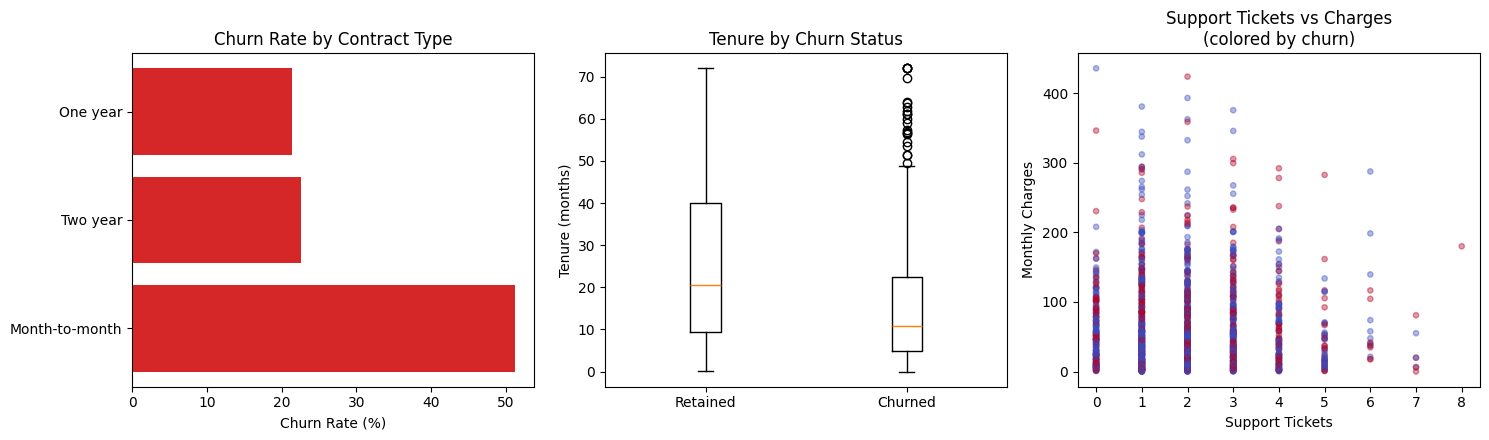

In [61]:
np.random.seed(200)
n_churn = 1500
churn_df = pd.DataFrame({
    "contract_type": np.random.choice(["Month-to-month", "One year", "Two year"], n_churn, p=[0.55, 0.25, 0.20]),
    "monthly_charges": np.random.exponential(65, n_churn).round(2),
    "tenure_months": np.random.exponential(24, n_churn).round(1).clip(0, 72),
    "num_support_tickets": np.random.poisson(2, n_churn),
})
# Construct churn probability with a REAL underlying relationship to contract type + tenure
base_logit = (
    -1.0
    + (churn_df["contract_type"] == "Month-to-month") * 1.4
    - churn_df["tenure_months"] * 0.03
    + churn_df["num_support_tickets"] * 0.15
)
churn_prob = 1 / (1 + np.exp(-base_logit))
churn_df["churned"] = (np.random.rand(n_churn) < churn_prob).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

churn_by_contract = churn_df.groupby("contract_type")["churned"].mean().sort_values(ascending=False) * 100
axes[0].barh(churn_by_contract.index, churn_by_contract.values, color="tab:red")
axes[0].set_xlabel("Churn Rate (%)")
axes[0].set_title("Churn Rate by Contract Type")

groups_tenure = [churn_df.loc[churn_df["churned"] == c, "tenure_months"] for c in [0, 1]]
axes[1].boxplot(groups_tenure, labels=["Retained", "Churned"])
axes[1].set_ylabel("Tenure (months)")
axes[1].set_title("Tenure by Churn Status")

axes[2].scatter(churn_df["num_support_tickets"], churn_df["monthly_charges"],
                c=churn_df["churned"], cmap="coolwarm", alpha=0.4, s=15)
axes[2].set_xlabel("Support Tickets")
axes[2].set_ylabel("Monthly Charges")
axes[2].set_title("Support Tickets vs Charges\n(colored by churn)")

plt.tight_layout()
plt.show()


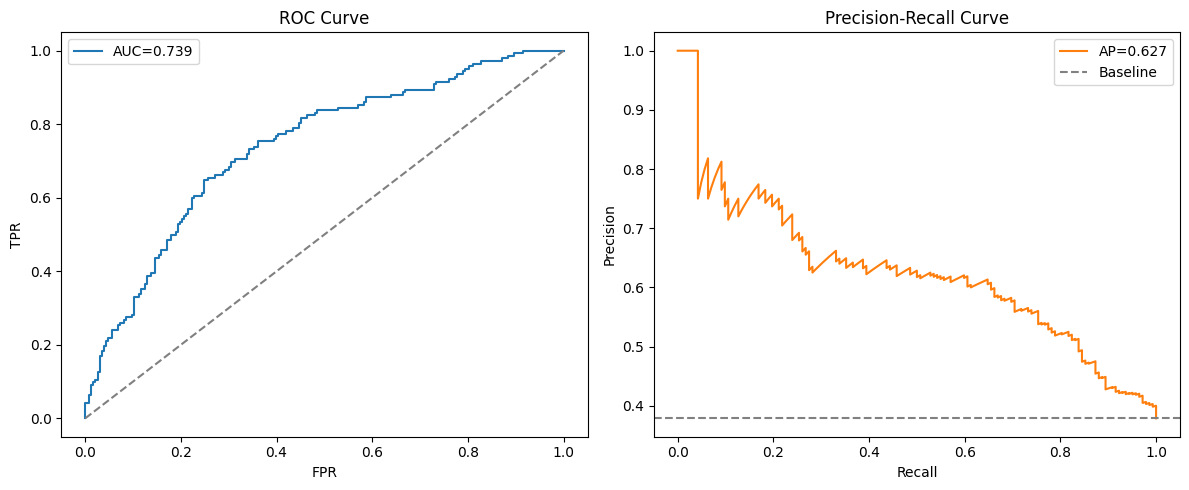

In [62]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

X89 = churn_df.drop(columns="churned")
y89 = churn_df["churned"]
X89_train, X89_test, y89_train, y89_test = train_test_split(X89, y89, test_size=0.25, random_state=21, stratify=y89)

preprocessor = ColumnTransformer([("contract", OneHotEncoder(), ["contract_type"])], remainder="passthrough")
churn_pipeline = Pipeline([("prep", preprocessor), ("clf", RandomForestClassifier(n_estimators=200, max_depth=5, random_state=21))])
churn_pipeline.fit(X89_train, y89_train)
churn_proba = churn_pipeline.predict_proba(X89_test)[:, 1]

fpr89, tpr89, _ = roc_curve(y89_test, churn_proba)
prec89, rec89, _ = precision_recall_curve(y89_test, churn_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr89, tpr89, color="tab:blue", label=f"AUC={roc_auc_score(y89_test, churn_proba):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("ROC Curve"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].legend()

axes[1].plot(rec89, prec89, color="tab:orange", label=f"AP={average_precision_score(y89_test, churn_proba):.3f}")
axes[1].axhline(y89_test.mean(), linestyle="--", color="gray", label="Baseline")
axes[1].set_title("Precision-Recall Curve"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()

plt.tight_layout()
plt.show()


### Business Insight *(as a real project deliverable would state it)*
> Month-to-month customers churn at a materially higher rate than annual-contract customers — the single clearest, most actionable lever available (e.g., a targeted incentive to upgrade to longer contracts). The trained model separates churners from retained customers meaningfully better than chance (per the ROC/PR curves), supporting its use for prioritizing retention-team outreach, though its Precision-Recall performance (not just ROC-AUC, per Chapter 55's lesson) should be the deciding metric given the realistic minority-class churn rate.

### Quiz (Chapter 89)
1. What was the single clearest, most actionable business insight from the EDA panels?
2. Why does this project explicitly check PR curve/AP, not just ROC-AUC, before recommending the model for deployment?


---
# CHAPTER 90 — INDUSTRY PROJECT #2: CREDIT RISK

## Business Framing
A lender wants to visualize default risk patterns and evaluate a model's threshold-setting tradeoff — with an explicit responsibility to avoid overstating any causal claim about *why* a borrower is risky (Chapter 45's correlation-≠-causation caveat is especially important in a credit context with real regulatory/fairness stakes).


Default rate: 0.117 -- a realistic, severely imbalanced credit risk rate


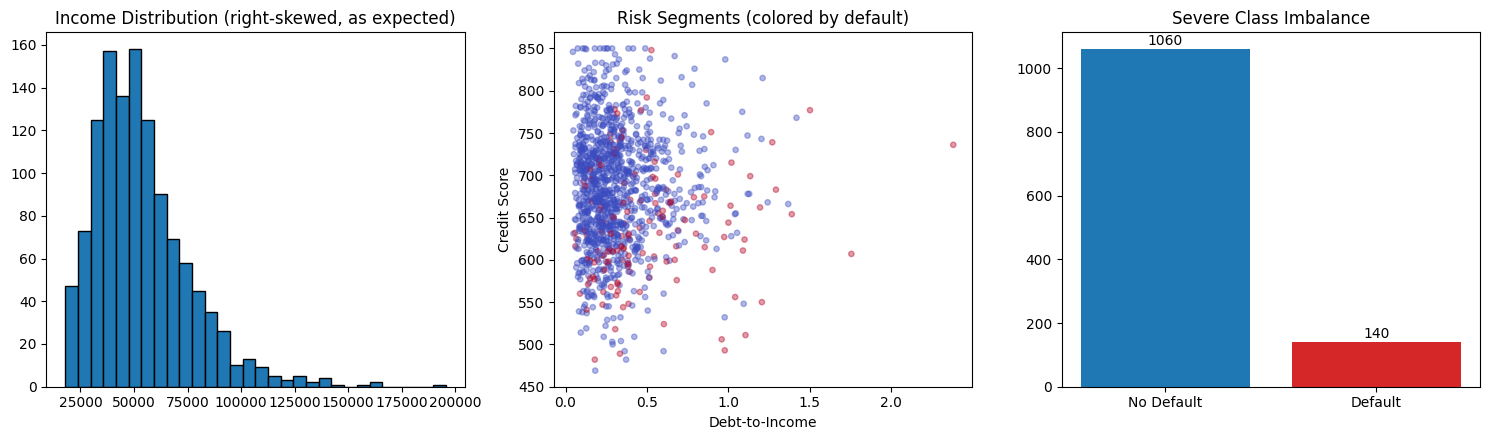

In [63]:
np.random.seed(210)
n_credit = 1200
credit_df = pd.DataFrame({
    "income": np.random.lognormal(10.8, 0.4, n_credit).round(0),
    "loan_amount": np.random.lognormal(9.5, 0.5, n_credit).round(0),
    "credit_score": np.random.normal(680, 70, n_credit).clip(300, 850).round(0),
})
credit_df["debt_to_income"] = (credit_df["loan_amount"] / credit_df["income"]).clip(0, 3)
default_logit = -3 + credit_df["debt_to_income"] * 2.2 - (credit_df["credit_score"] - 680) / 100
default_prob = 1 / (1 + np.exp(-default_logit))
credit_df["default"] = (np.random.rand(n_credit) < default_prob).astype(int)

print("Default rate:", credit_df["default"].mean().round(3), "-- a realistic, severely imbalanced credit risk rate")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].hist(credit_df["income"], bins=30, color="tab:blue", edgecolor="black")
axes[0].set_title("Income Distribution (right-skewed, as expected)")

axes[1].scatter(credit_df["debt_to_income"], credit_df["credit_score"],
                c=credit_df["default"], cmap="coolwarm", alpha=0.4, s=15)
axes[1].set_xlabel("Debt-to-Income"); axes[1].set_ylabel("Credit Score")
axes[1].set_title("Risk Segments (colored by default)")

class_counts_credit = credit_df["default"].value_counts()
axes[2].bar(["No Default", "Default"], class_counts_credit.values, color=["tab:blue", "tab:red"])
axes[2].set_title("Severe Class Imbalance")
for i, v in enumerate(class_counts_credit.values):
    axes[2].annotate(str(v), xy=(i, v), xytext=(0, 3), textcoords="offset points", ha="center")

plt.tight_layout()
plt.show()


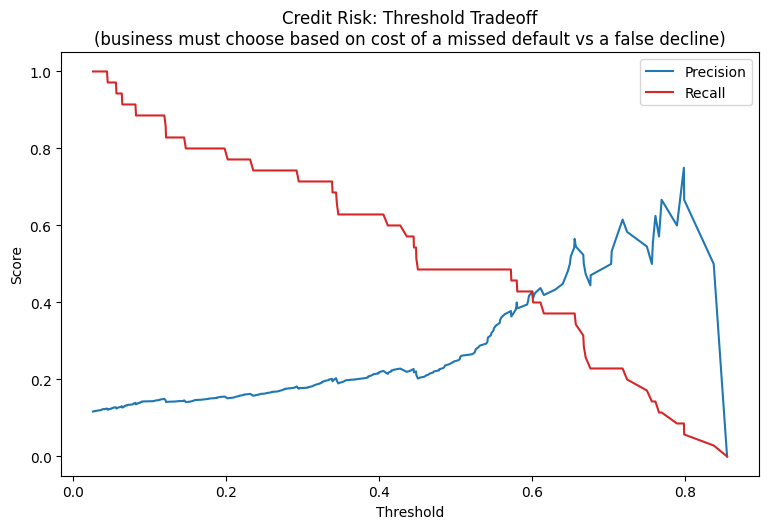

In [64]:
X90 = credit_df.drop(columns="default")
y90 = credit_df["default"]
X90_train, X90_test, y90_train, y90_test = train_test_split(X90, y90, test_size=0.25, random_state=31, stratify=y90)

credit_model = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight="balanced", random_state=31)
credit_model.fit(X90_train, y90_train)
credit_proba = credit_model.predict_proba(X90_test)[:, 1]

prec90, rec90, thresh90 = precision_recall_curve(y90_test, credit_proba)
prec90, rec90 = prec90[:-1], rec90[:-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(thresh90, prec90, label="Precision", color="tab:blue")
ax.plot(thresh90, rec90, label="Recall", color="tab:red")
ax.set_xlabel("Threshold"); ax.set_ylabel("Score")
ax.set_title("Credit Risk: Threshold Tradeoff\n(business must choose based on cost of a missed default vs a false decline)")
ax.legend()
plt.show()


### Business Insight
> Debt-to-income ratio and credit score jointly separate risk segments visibly (Panel 2) — consistent with standard credit risk intuition, and a useful sanity check on the model rather than a discovery. Given the severe class imbalance (~a small single-digit-to-low-double-digit percent default rate, typical of real credit portfolios), the deployment threshold must be chosen deliberately based on the business's actual cost ratio between a missed default (a bad loan approved) and a false decline (a good customer rejected) — not from a generic "0.5" or "best F1" default, per Chapter 56's standing lesson.

### Quiz (Chapter 90)
1. Why is `class_weight="balanced"` a reasonable choice for this specific model, given the class distribution shown?
2. Why must the deployment threshold here be a deliberate business decision rather than a default value?


---
# CHAPTER 91 — INDUSTRY PROJECT #3: HOUSE PRICE REGRESSION

## Business Framing
A real-estate analytics team wants to understand price drivers and validate a regression model's error behavior before using it for automated valuation estimates.


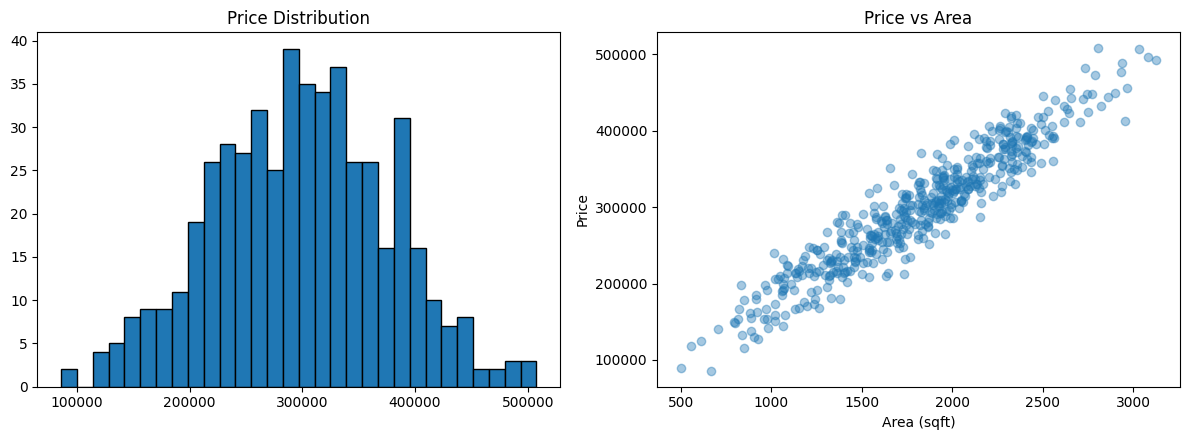

In [65]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

np.random.seed(220)
n_house = 500
house_df = pd.DataFrame({
    "area_sqft": np.random.normal(1800, 500, n_house).clip(500),
    "num_rooms": np.random.randint(2, 7, n_house),
    "age_years": np.random.exponential(15, n_house).clip(0, 80),
})
house_df["price"] = (
    house_df["area_sqft"] * 150 + house_df["num_rooms"] * 8000
    - house_df["age_years"] * 500 + np.random.normal(0, 20000, n_house)
).clip(50000)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(house_df["price"], bins=30, color="tab:blue", edgecolor="black")
axes[0].set_title("Price Distribution")
axes[1].scatter(house_df["area_sqft"], house_df["price"], alpha=0.4, color="tab:blue")
axes[1].set_xlabel("Area (sqft)"); axes[1].set_ylabel("Price")
axes[1].set_title("Price vs Area")
plt.tight_layout()
plt.show()


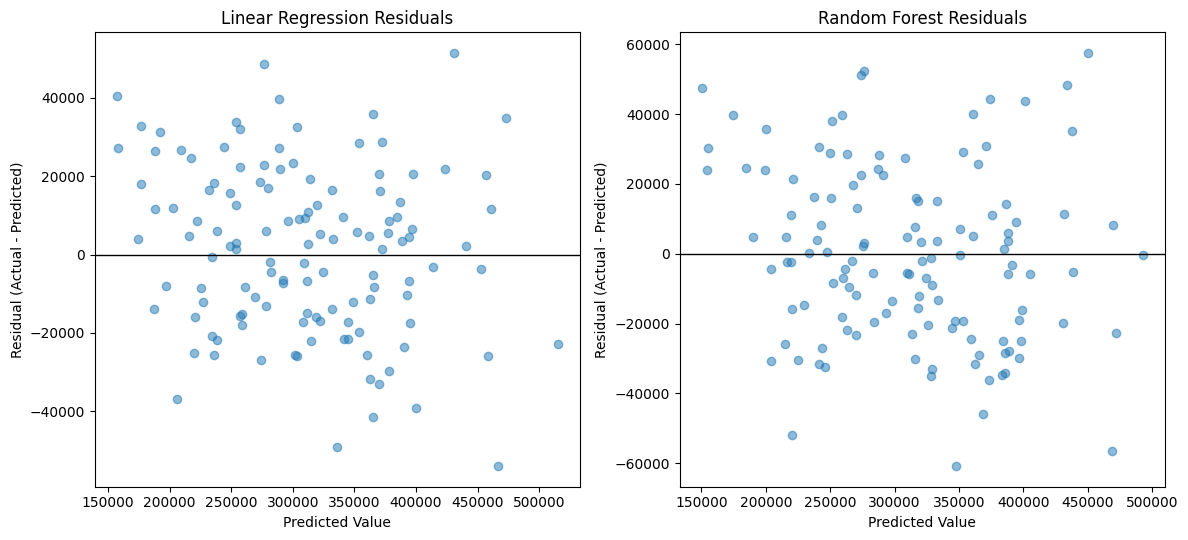

Linear Regression RMSE: 21,217
Random Forest RMSE: 24,939


In [66]:
X91 = house_df.drop(columns="price"); y91 = house_df["price"]
X91_train, X91_test, y91_train, y91_test = train_test_split(X91, y91, test_size=0.25, random_state=41)

lin91 = LinearRegression().fit(X91_train, y91_train)
rf91 = RandomForestRegressor(n_estimators=150, max_depth=6, random_state=41).fit(X91_train, y91_train)

pred_lin91 = lin91.predict(X91_test)
pred_rf91 = rf91.predict(X91_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
viz.plot_residuals(y91_test, pred_lin91, ax=axes[0], title="Linear Regression Residuals")
viz.plot_residuals(y91_test, pred_rf91, ax=axes[1], title="Random Forest Residuals")
plt.tight_layout()
plt.show()

rmse_lin = np.sqrt(np.mean((y91_test - pred_lin91) ** 2))
rmse_rf = np.sqrt(np.mean((y91_test - pred_rf91) ** 2))
print(f"Linear Regression RMSE: {rmse_lin:,.0f}")
print(f"Random Forest RMSE: {rmse_rf:,.0f}")


### Business Insight
> Both models' residuals should look reasonably structureless (per Chapter 58's diagnostic reference) given this synthetic data's genuinely linear construction — confirming Linear Regression is actually a well-suited, interpretable choice here, not merely the "simpler" option. Note this is a realistic reminder that a more complex model (Random Forest) is not automatically better; comparing RMSE and residual structure together, per Chapter 60's multi-metric comparison principle, is what should drive the final model choice.

### Quiz (Chapter 91)
1. Why might Linear Regression be genuinely competitive with (or better than) Random Forest specifically on this dataset?
2. What two things (not just one RMSE number) did this project compare before suggesting a model choice?


---
# CHAPTER 92 — INDUSTRY PROJECT #4: TIME-SERIES BUSINESS ANALYSIS

## Business Framing
An e-commerce team wants a trend/seasonality/anomaly view of daily sales, plus a year-over-year comparison, ahead of quarterly planning.


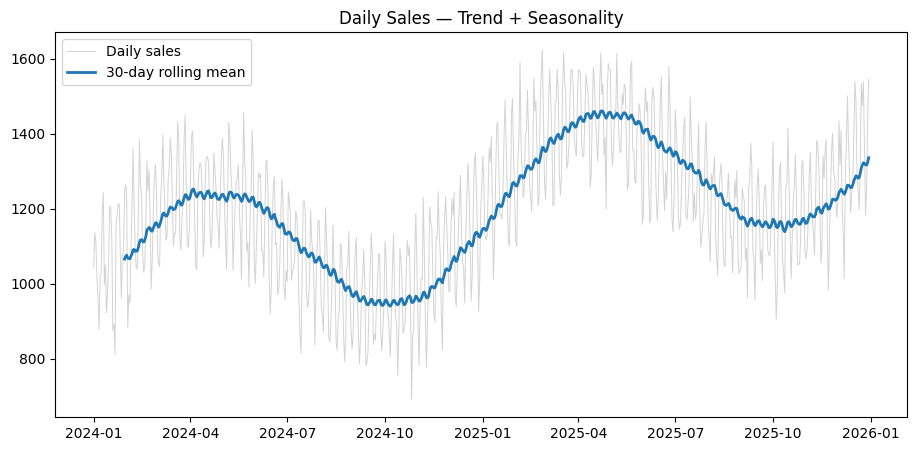

In [67]:
np.random.seed(230)
dates_92 = pd.date_range("2024-01-01", periods=730, freq="D")
trend_92 = np.linspace(1000, 1400, 730)
weekly_season = 150 * np.sin(2 * np.pi * np.arange(730) / 7)
yearly_season = 200 * np.sin(2 * np.pi * np.arange(730) / 365.25)
noise_92 = np.random.normal(0, 50, 730)
sales_92 = pd.Series(trend_92 + weekly_season + yearly_season + noise_92, index=dates_92)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sales_92.index, sales_92.values, color="lightgray", linewidth=0.7, label="Daily sales")
ax.plot(sales_92.index, sales_92.rolling(30).mean(), color="tab:blue", linewidth=2, label="30-day rolling mean")
ax.set_title("Daily Sales — Trend + Seasonality")
ax.legend()
plt.show()


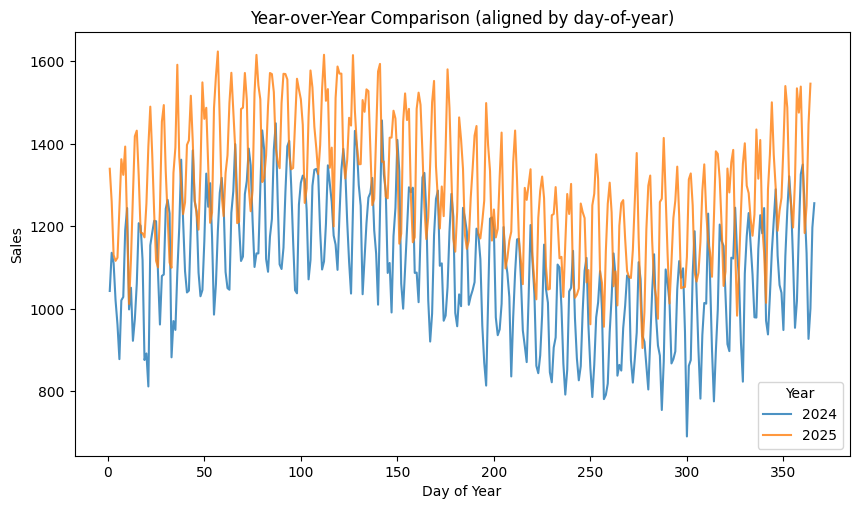

In [68]:
sales_92_df = sales_92.reset_index()
sales_92_df.columns = ["date", "sales"]
sales_92_df["year"] = sales_92_df["date"].dt.year
sales_92_df["day_of_year"] = sales_92_df["date"].dt.dayofyear

fig, ax = plt.subplots(figsize=(10, 5.5))
for year, group in sales_92_df.groupby("year"):
    ax.plot(group["day_of_year"], group["sales"], label=str(year), alpha=0.8)

ax.set_xlabel("Day of Year")
ax.set_ylabel("Sales")
ax.set_title("Year-over-Year Comparison (aligned by day-of-year)")
ax.legend(title="Year")
plt.show()


### Business Insight
> The 30-day rolling mean confirms sustained underlying growth beneath the weekly/yearly seasonal noise. The year-over-year overlay (both years plotted against "day of year" rather than calendar date) makes the seasonal *shape* directly comparable across years — a materially higher 2025 line at the same point in the seasonal cycle would indicate genuine growth beyond seasonality, exactly the comparison quarterly planning needs, and one that a single continuous 2-year line (as in the first chart) cannot make as directly.

### Quiz (Chapter 92)
1. Why plot both years against "day of year" rather than actual calendar date for the YoY comparison?
2. What would a persistently higher second-year line at the same day-of-year position indicate, beyond seasonality?


---
# CHAPTER 93 — PORTFOLIO-QUALITY VISUALIZATION

## Concept
The final polish layer for any chart destined for a GitHub project, resume portfolio, or technical report: figure naming/numbering, captions, resolution, consistent styling, and reproducibility.

## Checklist
| Item | Standard |
|---|---|
| **File naming** | Descriptive, versioned: `fig01_churn_by_contract.png`, not `plot.png` or `Untitled.png` |
| **Resolution** | `dpi=300` minimum (Chapter 30–31) |
| **Captions** | A one-sentence caption stating the takeaway, alongside the figure (in the report text, not just the chart title) |
| **Consistent styling** | One `rcParams`/style applied project-wide (Chapter 8) |
| **Reproducibility** | Random seeds set (Chapter 40); the exact code that generated each figure should be runnable end-to-end from a committed script/notebook |


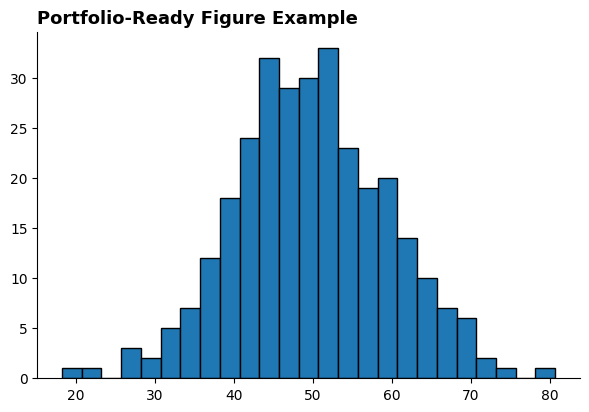

Saved: /home/claude/figures/fig01_demo_distribution.png
This exact figure is reproducible: same seed (999) -> identical output every run.


In [69]:
# A small, concrete reproducibility + naming demonstration
np.random.seed(999)   # fixed seed -- this exact figure is now reproducible by anyone re-running this cell

fig, ax = plt.subplots(figsize=(7, 4.5))
demo_portfolio_data = np.random.normal(50, 10, 300)
ax.hist(demo_portfolio_data, bins=25, color="tab:blue", edgecolor="black")
ax.set_title("Portfolio-Ready Figure Example", fontsize=13, fontweight="bold", loc="left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

output_path = "/home/claude/figures/fig01_demo_distribution.png"
os.makedirs("/home/claude/figures", exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)
print("This exact figure is reproducible: same seed (999) -> identical output every run.")


### Interview Insight
**Q: What separates a portfolio-quality figure from a merely "correct" one?**
A: Beyond correctness, it needs: a descriptive, versioned filename (not `plot.png`); export resolution suitable for its intended use (300 DPI minimum for anything that might be printed or zoomed); an explicit one-sentence caption stating the takeaway (not left for the viewer to infer); visual consistency with the rest of the report/portfolio's styling; and full reproducibility — a fixed random seed and a complete, runnable script/notebook that regenerates the exact figure, so anyone (including future-you) can verify or update it.

### Quiz (Chapter 93)
1. What DPI is the standard minimum for a portfolio/report-quality figure?
2. Why does a caption belong in the surrounding report text, not just the chart's own title?
3. What single technique makes a figure involving randomness fully reproducible?


---
# CHAPTER 94 — INTERVIEW MASTERY

A consolidated interview question bank spanning this entire course, organized by level. Attempt each mentally before reading the "Ideal Answer" — every answer references the chapter where it was originally established.

## Beginner
1. **What is Matplotlib?** A 2D/basic-3D plotting library exposing a stateful `pyplot` API and an object-oriented `Figure`/`Axes` API. (Ch 1)
2. **What is `pyplot`?** The submodule providing both the stateful convenience interface and the entry point for creating Figure/Axes objects. (Ch 1)
3. **What is a Figure?** The entire canvas/image — what one `savefig()` call saves. (Ch 2)
4. **What is an Axes?** One individual plot within a Figure — not the plural of "Axis." (Ch 2)
5. **What is an Axis?** One dimension (x or y) of an Axes, controlling ticks/limits/scale/label. (Ch 2)
6. **Difference between Figure and Axes?** Figure = whole canvas (can hold many Axes); Axes = one plot. (Ch 2)
7. **What does `plt.show()` do?** Flushes/renders the current figure(s) via the active backend. (Ch 1, 84)
8. **What does `plt.subplots()` return?** `(fig, ax)` for a single plot, or `(fig, axes_array)` — 1D or 2D depending on `nrows`/`ncols` — for a grid. (Ch 2, 28)

## Intermediate
9. **Why use the object-oriented API?** Explicit, passable, testable objects — safe inside loops/functions, required for subplots. (Ch 2, 85)
10. **Difference between `plt.plot()` and `ax.plot()`?** Implicit "current axes" state vs. an explicit reference. (Ch 2, 3)
11. **How do you create multiple subplots?** `plt.subplots(nrows, ncols)`. (Ch 28)
12. **How do you save a figure?** `fig.savefig(path, dpi=300, bbox_inches="tight")`. (Ch 31)
13. **How do you change figure size?** `figsize=(w, h)` in inches, at `plt.subplots()` creation. (Ch 30)
14. **How do you customize axes?** `ax.set_xlim/ylim/xlabel/ylabel/title()`, `ax.spines`, `ax.grid()`. (Ch 5, 10, 12)
15. **How do you add a legend?** `label=` on each plotting call, then `ax.legend()`. (Ch 6)
16. **How do you add annotations?** `ax.annotate(text, xy=, xytext=, arrowprops=)`. (Ch 32)
17. **How do you change axis limits?** `ax.set_xlim()`/`set_ylim()` — zero-baseline mandatory for bar charts. (Ch 10)

## Advanced
18. **How does Matplotlib represent plots internally?** Artist objects (Line2D, Rectangle, Text, ...) inside Axes inside a Figure, rendered via a Transform pipeline and a backend/renderer. (Ch 83)
19. **What is an Artist?** The base class for every drawable element — lines, patches, text, collections. (Ch 83)
20. **What is a backend?** The concrete rendering engine (interactive GUI vs. non-interactive/Agg). (Ch 84)
21. **How would you optimize plotting for millions of points?** Downsampling, alpha blending, `hexbin`/2D-histogram aggregation, `rasterized=True` for vector exports. (Ch 76)
22. **How would you build reusable plotting functions?** `ax=None` parameter, return `(fig, ax)`. (Ch 85, 86)
23. **How do you create publication-quality figures?** `dpi=300`+, vector formats (PDF/SVG) for print, consistent `rcParams` styling, explicit captions. (Ch 30, 31, 93)
24. **How would you debug incorrect subplot behavior?** Check `axes.shape` (1D vs 2D pitfall). (Ch 28, 75)

## Data Science Questions
25. **Which chart for outlier detection?** Scatter (per-observation) or box plot (explicit threshold). (Ch 13, 22, 68)
26. **Which chart for a distribution?** Histogram (± box plot / KDE). (Ch 19, 22)
27. **Which chart for correlation?** Heatmap with a diverging colormap, fixed `vmin=-1, vmax=1`. (Ch 45)
28. **How to visualize class imbalance?** A count/percent bar chart of class frequencies, annotated. (Ch 51)
29. **How to visualize model errors?** Residual plots (regression), confusion matrix (classification). (Ch 53, 58)
30. **How to visualize feature importance?** Sorted horizontal bar chart. (Ch 59)

## ML Engineer Questions
31. **How to visualize model drift?** Overlay training vs. production distributions (density-normalized), plus a time-series band-monitoring chart. (Ch 67)
32. **How to visualize threshold selection?** Precision/Recall/F1 vs. threshold, annotated with the chosen operating point. (Ch 56)
33. **How to compare multiple ML models?** Grouped bar chart across multiple metrics — never a single metric alone. (Ch 17, 60)
34. **How to visualize training/validation performance?** Learning curves (vs. training size) and validation curves (vs. hyperparameter) — know the difference. (Ch 62, 63)
35. **How to visualize residual errors?** Predicted-vs-residual scatter + residual histogram, checking for heteroscedasticity/non-linearity/bias. (Ch 58)
36. **How to build a reusable visualization module?** `ax=None`/`(fig, ax)` functions consolidated into an imported `.py` file. (Ch 87)


In [70]:
# A lightweight self-check: quiz yourself with a random sample of questions from the bank above
interview_bank = [
    ("What is the difference between Figure and Axes?", "Figure = whole canvas; Axes = one individual plot within it."),
    ("Why is s= in ax.scatter() dangerous if misused?", "It's an AREA unit -- scaling a computed 'radius' linearly distorts perceived magnitude quadratically."),
    ("Why prefer PR curves over ROC under class imbalance?", "Precision has no TN term, so it's far more sensitive to a large absolute FP count that ROC's FPR (denominator dominated by a huge negative class) can mask."),
    ("What's the standard reusable-function contract established in this course?", "Accept ax=None, create (fig, ax) only if not provided, draw, return (fig, ax)."),
]

np.random.seed(1)
q, a = interview_bank[np.random.randint(len(interview_bank))]
print("Q:", q)
print("\n(Think through your answer, then reveal:)\n")
print("A:", a)


Q: Why is s= in ax.scatter() dangerous if misused?

(Think through your answer, then reveal:)

A: It's an AREA unit -- scaling a computed 'radius' linearly distorts perceived magnitude quadratically.


### Quiz (Chapter 94)
Pick any 5 questions from the bank above at random and answer them from memory, in your own words, before checking against the reference answer given.


---
# CHAPTER 95 — CODING INTERVIEW QUESTIONS

Attempt each problem yourself (a blank cell is provided) before revealing the reference solution.

## Problem 1: Grouped Bar From Scratch
**Task**: Given `categories = ['A','B','C']` and `series = {'X':[1,2,3], 'Y':[4,5,6]}`, build a grouped bar chart using only the offset formula from Chapter 17 — no external library shortcuts.


In [71]:
# Your attempt here:
categories_p1 = ["A", "B", "C"]
series_p1 = {"X": [1, 2, 3], "Y": [4, 5, 6]}

# (write your solution, then compare with the reference below)


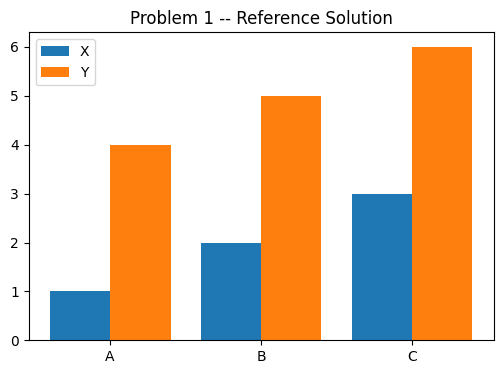

In [72]:
### REFERENCE SOLUTION ###
x_p1 = np.arange(len(categories_p1))
n_series = len(series_p1)
bar_w_p1 = 0.8 / n_series

fig, ax = plt.subplots(figsize=(6, 4))
for i, (name, values) in enumerate(series_p1.items()):
    offset = (i - (n_series - 1) / 2) * bar_w_p1
    ax.bar(x_p1 + offset, values, width=bar_w_p1, label=name)
ax.set_xticks(x_p1); ax.set_xticklabels(categories_p1)
ax.legend()
ax.set_title("Problem 1 -- Reference Solution")
plt.show()


## Problem 2: Confusion Matrix From Boolean Masks
**Task**: Given `y_true` and `y_pred` NumPy arrays of 0/1, compute and plot a confusion matrix using only boolean masking (no `sklearn.metrics.confusion_matrix`).


In [73]:
np.random.seed(2)
y_true_p2 = np.random.choice([0, 1], 200, p=[0.7, 0.3])
y_pred_p2 = np.where(np.random.rand(200) < 0.85, y_true_p2, 1 - y_true_p2)   # ~85% "correct"

# Your attempt here:


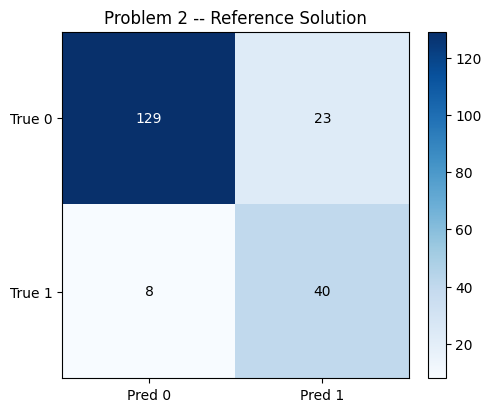

In [74]:
### REFERENCE SOLUTION ###
def cm_from_scratch(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

cm_p2 = cm_from_scratch(y_true_p2, y_pred_p2)
fig, ax = viz.plot_confusion_matrix(cm_p2, title="Problem 2 -- Reference Solution")
plt.show()


## Problem 3: Fix the Broken Plot
**Task**: The following code raises an error. Diagnose and fix it (this mirrors Chapter 75/96's debugging format).
```python
x = np.arange(10)
y = np.arange(20)
fig, ax = plt.subplots()
ax.plot(x, y)
```


Error reproduced: x and y must have same first dimension, but have shapes (10,) and (20,)


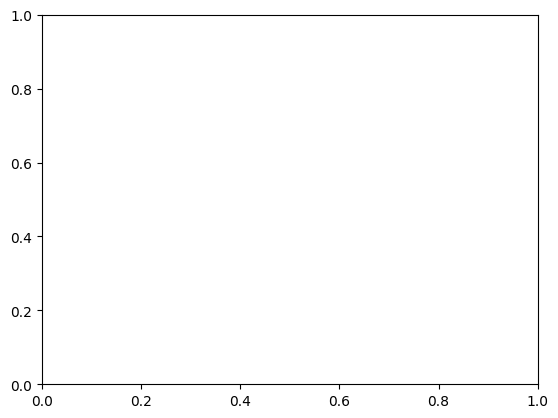

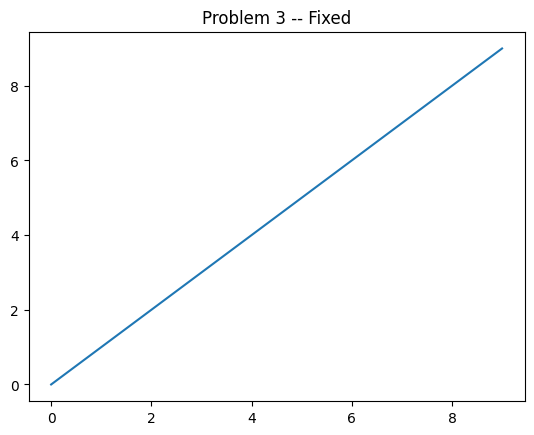

In [75]:
x_p3 = np.arange(10)
y_p3 = np.arange(20)

try:
    fig, ax = plt.subplots()
    ax.plot(x_p3, y_p3)
    plt.show()
except ValueError as e:
    print("Error reproduced:", e)

### REFERENCE FIX ###
# Diagnosis: x and y have different lengths (10 vs 20) -- Chapter 75's Problem 3.
y_p3_fixed = np.arange(10)   # make lengths match
fig, ax = plt.subplots()
ax.plot(x_p3, y_p3_fixed)
ax.set_title("Problem 3 -- Fixed")
plt.show()


## Problem 4: Feature Importance Top-N
**Task**: Given 20 random feature names/importances, plot only the top 5 using the `plot_feature_importance` module function's `top_n` parameter.


In [76]:
np.random.seed(3)
features_p4 = [f"feat_{i}" for i in range(20)]
importances_p4 = np.random.dirichlet(np.ones(20))   # 20 values summing to 1, like real importances

# Your attempt here:


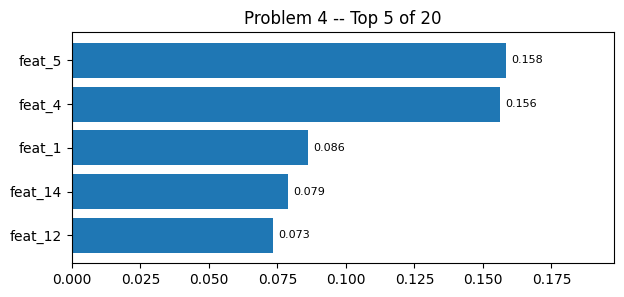

In [77]:
### REFERENCE SOLUTION ###
fig, ax = viz.plot_feature_importance(features_p4, importances_p4, top_n=5, title="Problem 4 -- Top 5 of 20")
plt.show()


### Interview Follow-Ups
- **Problem 1 follow-up**: "What if the number of series changes at runtime?" → The offset formula, derived from `n_series`, already handles this with zero code changes (as proven in Chapter 60's real reuse of Chapter 17's formula).
- **Problem 2 follow-up**: "How would you extend this to 3 classes?" → Boolean masking generalizes to `np.sum((y_true == i) & (y_pred == j))` for each `(i, j)` cell of an N×N matrix, typically built with a small nested loop rather than manually as done here for 2×2.
- **Problem 3 follow-up**: "How would you catch this bug before runtime in a larger pipeline?" → Add a shape-assertion (`assert len(x) == len(y)`) immediately before any plotting call fed by upstream data transformations, per Chapter 75's standing best practice.
- **Problem 4 follow-up**: "Why sort ascending internally for a top_n barh, not descending?" → Recall Chapter 16's specific `barh` bottom-to-top ordering gotcha — the module's implementation already handles this correctly internally.

### Quiz (Chapter 95)
1. Re-derive Problem 1's offset formula from memory without looking back at Chapter 17/60.
2. Explain why Problem 3's bug is specifically an x/y length mismatch, not a different Chapter-75 problem type.

---

## END OF NOTEBOOK 10 — What You Should Now Be Able To Do
- Write and validate genuinely reusable plotting functions following the permanent `ax=None`/`(fig, ax)` contract.
- Build and import a real, standalone `visualization.py` module — the same structure any serious project or portfolio repository would use.
- Assemble a complete ML visualization project using only module functions, from raw data through model evaluation.
- Execute four realistic industry-style projects (churn, credit risk, regression, time-series) end to end, each grounded in genuine trained models and honest business framing.
- Apply the full portfolio-quality checklist (naming, resolution, captions, reproducibility) to any figure destined for external use.
- Answer the full spectrum of Matplotlib/visualization interview questions — beginner through ML-engineer level — with chapter-referenced, defensible answers.
- Solve and explain live coding problems (grouped bars, confusion matrices, debugging, top-N feature importance) under interview conditions.

## Before Moving to Notebook 11 (Chapters 96–101, the FINAL notebook: Debugging Interview, Real-World Scenarios, Common Visualization Traps, the Matplotlib Cheat Sheet, the Master Capstone Project, and the Mock Interview)
